# Exercise 56 – Classification in two dimensions

**Week 11 · Classification**

1. Three Gaussian clouds of points are separated by a linear classifier
   trained with the cross-entropy loss.
2. Points in the plane are labelled by the value of Himmelblau's function
   (three level sets). The regions are curved, so a linear classifier is not
   enough – networks with hidden layers are needed.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from matplotlib.colors import ListedColormap
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, random_split

from comphy.models import MLP
from comphy.plotting import setup_axes
from comphy.training import evaluate, train

torch.manual_seed(0)
CMAP = ListedColormap(["C0", "C1", "C2"])


def decision_regions(ax, model, lims=(-9, 9), step=0.05):
    grid = torch.arange(lims[0], lims[1], step)
    X1, X2 = torch.meshgrid(grid, grid, indexing="ij")
    with torch.no_grad():
        labels = model(torch.stack([X1.flatten(), X2.flatten()], dim=1)).argmax(dim=1)
    ax.contourf(X1, X2, labels.reshape(X1.shape), levels=[-0.5, 0.5, 1.5, 2.5],
                cmap=CMAP, alpha=0.35)

## 1. Three Gaussian clouds

In [2]:
means = torch.tensor([[-2.0, 3.0], [0.5, -3.0], [3.0, 1.0]])
points = torch.cat([m + 2 * torch.randn(100, 2) for m in means])
labels = torch.arange(3).repeat_interleave(100)

classifier = MLP(n_in=2, n_out=3, hidden=())          # a single linear layer
optimizer = torch.optim.Adam(classifier.parameters(), lr=0.01)
for _ in range(1000):
    optimizer.zero_grad()
    loss = nn.functional.cross_entropy(classifier(points), labels)
    loss.backward()
    optimizer.step()
predicted = classifier.predict_label(points)
print(f"training accuracy: {(predicted == labels).float().mean():.1%}")

training accuracy: 86.3%


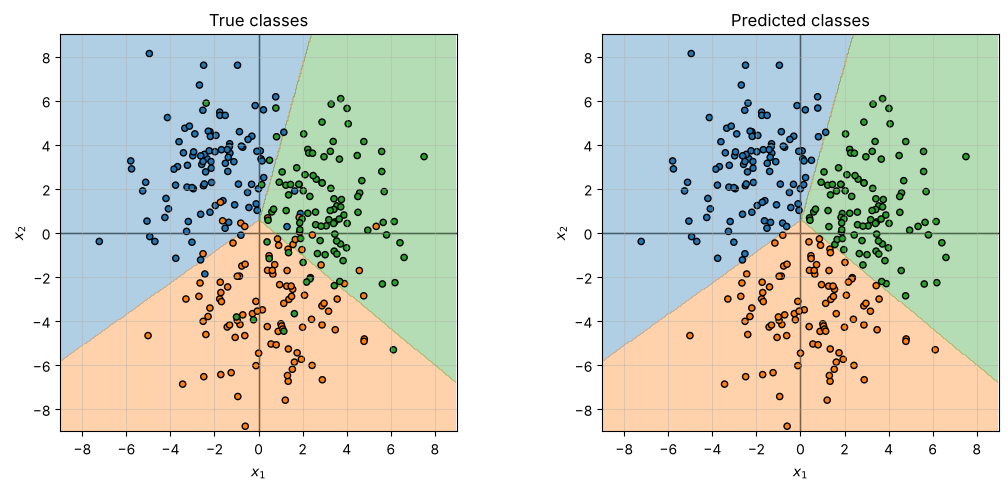

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, lab, title in zip(axes, [labels, predicted], ["True classes", "Predicted classes"]):
    decision_regions(ax, classifier)
    ax.scatter(*points.T, c=lab, cmap=CMAP, edgecolor="black", s=20)
    setup_axes(ax, xlim=(-9, 9), ylim=(-9, 9), xlabel="$x_1$", ylabel="$x_2$",
               title=title, equal=True)
fig.tight_layout()
plt.show()

The decision boundaries of a linear classifier are straight lines.

## 2. Level sets of Himmelblau's function

Label 0 where $f \le 25$, label 1 where $25 < f \le 300$ and label 2 elsewhere.

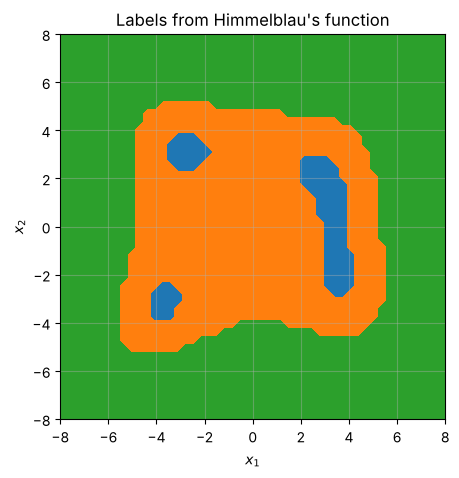

In [4]:
def himmelblau(x1, x2):
    return (x1**2 + x2 - 11) ** 2 + (x1 + x2**2 - 7) ** 2


grid = torch.linspace(-8, 8, 50)
X1, X2 = torch.meshgrid(grid, grid, indexing="ij")
f = himmelblau(X1, X2)
y = torch.where(f <= 25, 0, torch.where(f <= 300, 1, 2)).flatten()
X = torch.stack([X1.flatten(), X2.flatten()], dim=1)

dataset = TensorDataset(X, y)
n_train, n_val = int(0.8 * len(dataset)), int(0.1 * len(dataset))
train_set, val_set, test_set = random_split(dataset, [n_train, n_val, len(dataset) - n_train - n_val])
train_loader = DataLoader(train_set, batch_size=128, shuffle=True)
val_loader = DataLoader(val_set, batch_size=128)
test_loader = DataLoader(test_set, batch_size=128)

fig, ax = plt.subplots(figsize=(5, 5))
ax.contourf(X1, X2, y.reshape(X1.shape), levels=[-0.5, 0.5, 1.5, 2.5], cmap=CMAP)
setup_axes(ax, xlim=(-8, 8), ylim=(-8, 8), xlabel="$x_1$", ylabel="$x_2$",
           title="Labels from Himmelblau's function", equal=True)
plt.show()

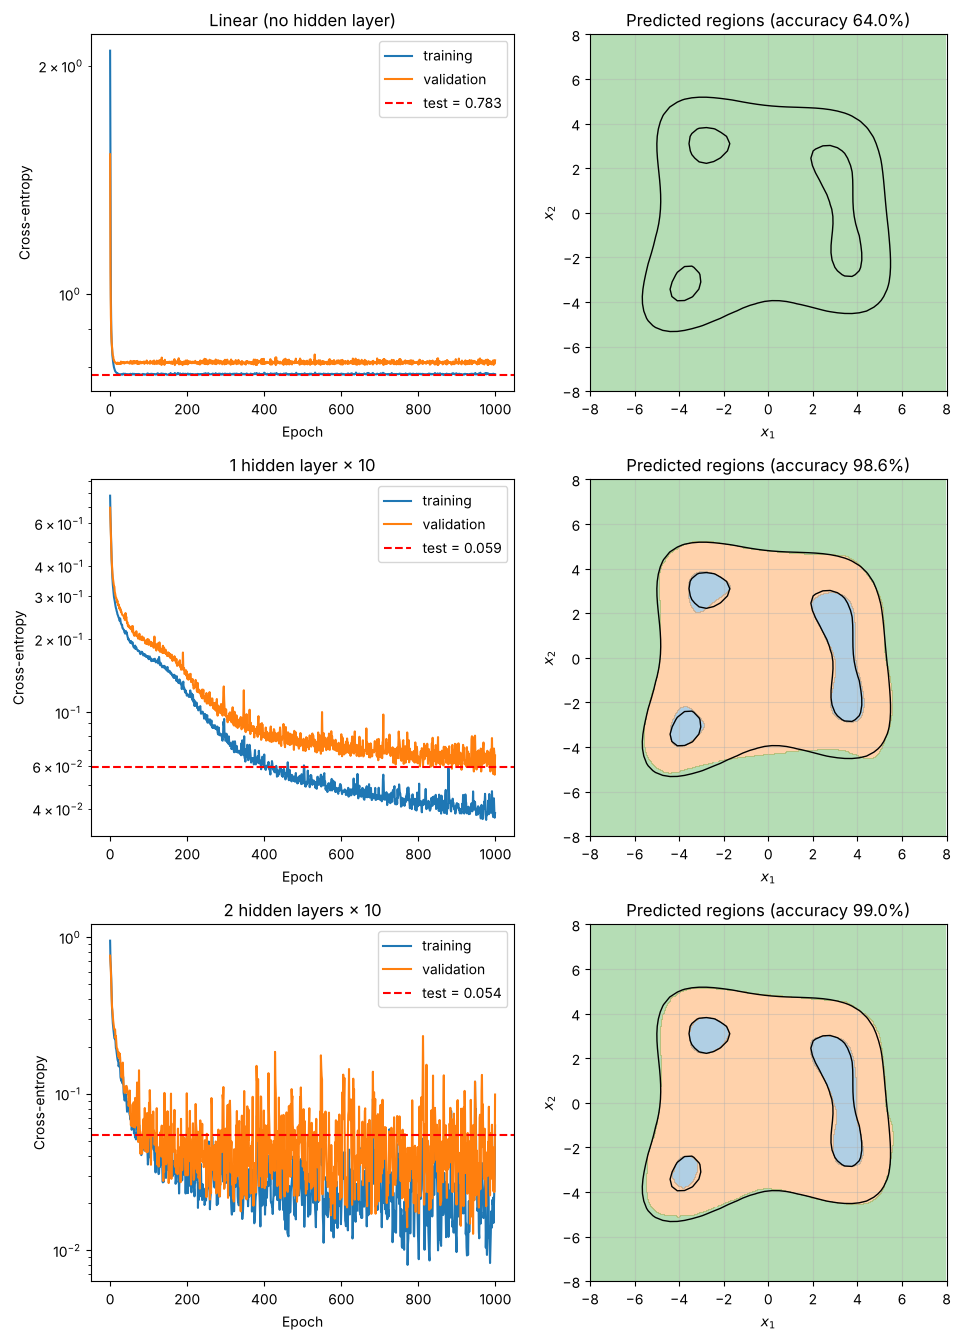

In [5]:
architectures = {"Linear (no hidden layer)": (), "1 hidden layer × 10": (10,),
                 "2 hidden layers × 10": (10, 10)}
loss_fn = nn.CrossEntropyLoss()

fig, axes = plt.subplots(len(architectures), 2, figsize=(10, 4.5 * len(architectures)))
for (name, hidden), (ax_loss, ax_map) in zip(architectures.items(), axes):
    torch.manual_seed(0)
    model = MLP(n_in=2, n_out=3, hidden=hidden, activation="silu")
    history = train(model, train_loader, val_loader, epochs=1000, lr=0.01, loss_fn=loss_fn,
                    restore_best=True)
    test_loss = evaluate(model, test_loader, loss_fn)
    accuracy = (model.predict_label(X) == y).float().mean()

    ax_loss.plot(history["train"], label="training")
    ax_loss.plot(history["val"], label="validation")
    ax_loss.axhline(test_loss, color="red", ls="--", label=f"test = {test_loss:.3f}")
    ax_loss.set(xlabel="Epoch", ylabel="Cross-entropy", title=name, yscale="log")
    ax_loss.legend()

    decision_regions(ax_map, model, lims=(-8, 8))
    ax_map.contour(X1, X2, f, levels=[25, 300], colors="black", linewidths=1)
    setup_axes(ax_map, xlim=(-8, 8), ylim=(-8, 8), xlabel="$x_1$", ylabel="$x_2$",
               title=f"Predicted regions (accuracy {accuracy:.1%})", zero_lines=False, equal=True)
fig.tight_layout()
plt.show()

Black lines are the true boundaries $f = 25$ and $f = 300$. A linear
classifier can only cut the plane with straight lines, so it cannot isolate
the curved regions and ends up predicting the majority class almost
everywhere. With one hidden layer of 10 SiLU neurons the network reproduces
the regions closely, and a second hidden layer gives a similar result.